# CreditWise Loan System

In [3]:
import sys
print(sys.executable)

c:\Users\jseha\AppData\Local\Programs\Python\Python314\python.exe


In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## Load Data

In [5]:
df = pd.read_csv("loan_approval_data.csv")
print(df.shape)
df.head()


(1000, 20)


,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


## Data Cleaning

In [6]:
print("Duplicates:", df.duplicated().sum())
display(df.isnull().sum())
display(df["Loan_Approved"].value_counts(dropna=False))

df = df.drop_duplicates().copy()
df = df.dropna(subset=["Loan_Approved"]).copy()

# Dataset labels are Yes/No; convert to the 1/0 target used in the project brief.
target_map = {"Yes": 1, "No": 0, "yes": 1, "no": 0, 1: 1, 0: 0}
df["Loan_Approved"] = df["Loan_Approved"].map(target_map)
df = df.dropna(subset=["Loan_Approved"]).copy()
df["Loan_Approved"] = df["Loan_Approved"].astype(int)

# Applicant_ID is an identifier, so it is not used as a predictor.
df = df.drop(columns=["Applicant_ID"], errors="ignore")
print("Cleaned shape:", df.shape)



Duplicates: 0


Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

Loan_Approved
No     652
Yes    298
NaN     50
Name: count, dtype: int64

Cleaned shape: (950, 19)


## Exploratory Data Analysis

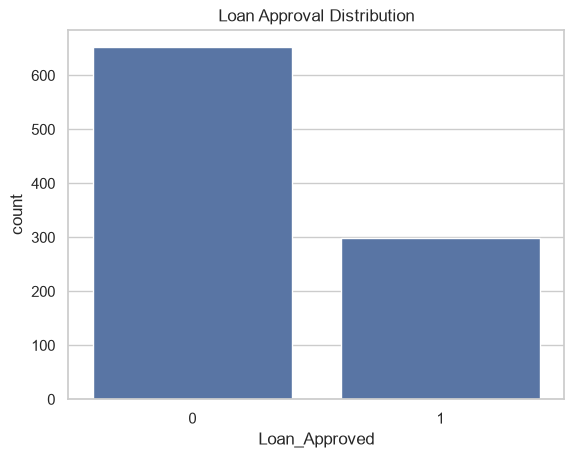

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Applicant_Income,902.0,NaN,NaN,NaN,10847.01663,5064.213641,2009.0,6742.0,10452.5,15174.25,19988.0
Coapplicant_Income,902.0,NaN,NaN,NaN,5061.607539,2937.413855,1.0,2469.75,5143.0,7589.75,9996.0
Employment_Status,906,4,Salaried,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,902.0,NaN,NaN,NaN,40.044346,11.194488,21.0,31.0,40.0,49.0,59.0
Marital_Status,902,2,Married,567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,903.0,NaN,NaN,NaN,1.460687,1.103489,0.0,1.0,1.0,2.0,3.0
Credit_Score,902.0,NaN,NaN,NaN,675.111973,71.327228,550.0,616.0,677.0,735.0,799.0
Existing_Loans,901.0,NaN,NaN,NaN,1.948946,1.406197,0.0,1.0,2.0,3.0,4.0
DTI_Ratio,903.0,NaN,NaN,NaN,0.347187,0.144522,0.1,0.22,0.34,0.48,0.6
Savings,901.0,NaN,NaN,NaN,9966.298557,5859.624544,73.0,4761.0,9910.0,15052.0,19996.0


In [7]:
sns.countplot(data=df, x="Loan_Approved")
plt.title("Loan Approval Distribution")
plt.show()

display(df.describe(include="all").T)


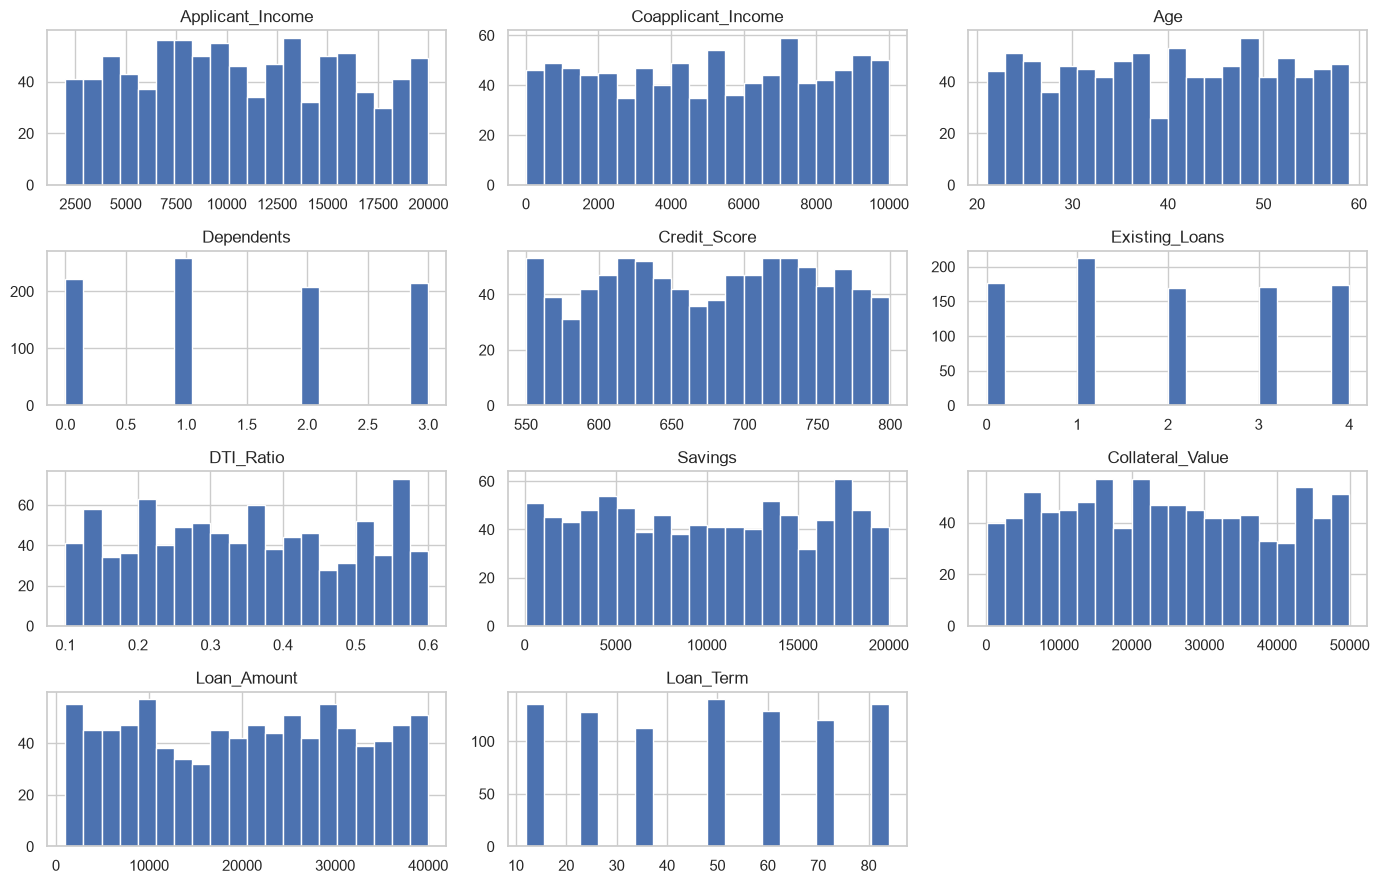

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns.drop("Loan_Approved", errors="ignore")
df[numeric_cols].hist(figsize=(14, 9), bins=20)
plt.tight_layout()
plt.show()


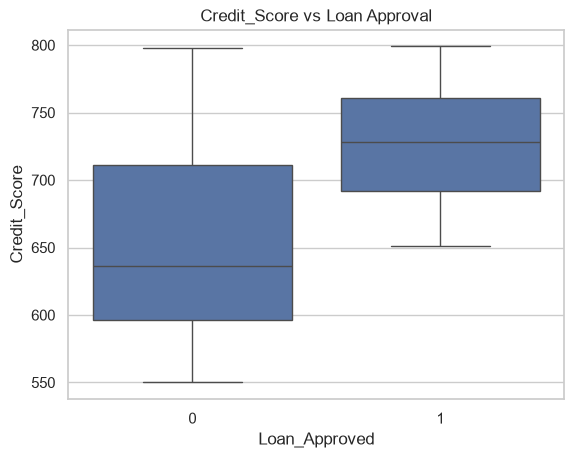

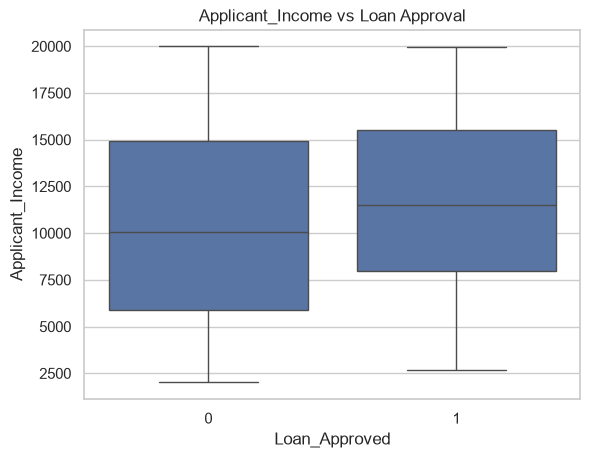

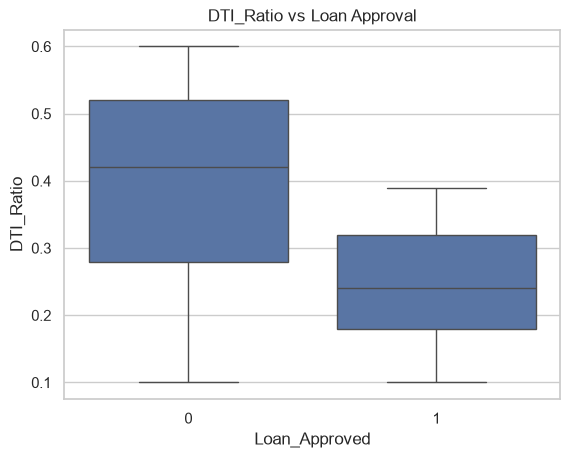

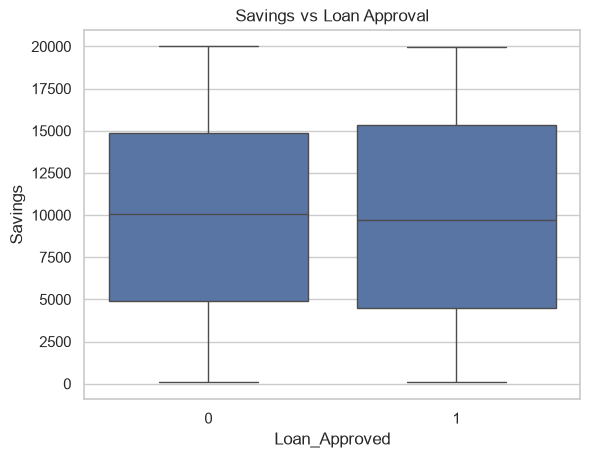

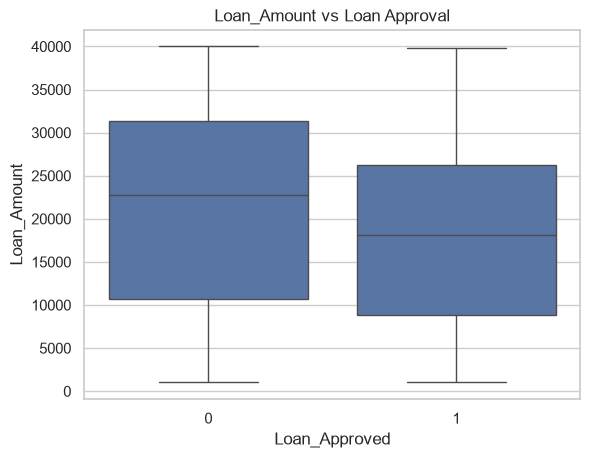

In [9]:
for col in ["Credit_Score", "Applicant_Income", "DTI_Ratio", "Savings", "Loan_Amount"]:
    if col in df.columns:
        sns.boxplot(data=df, x="Loan_Approved", y=col)
        plt.title(f"{col} vs Loan Approval")
        plt.show()


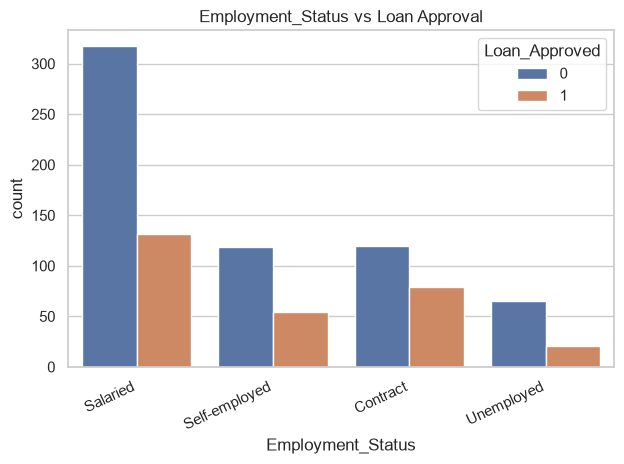

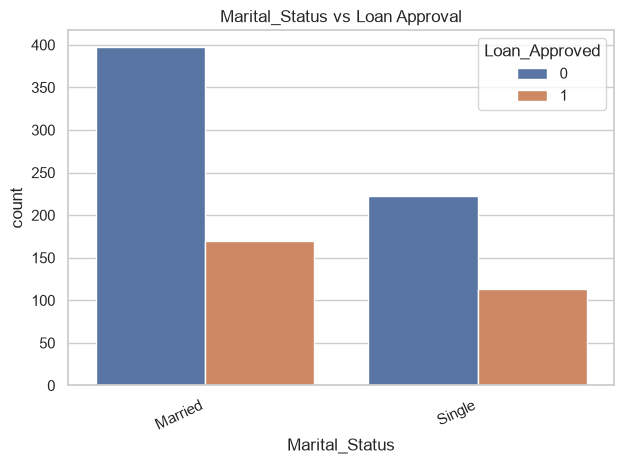

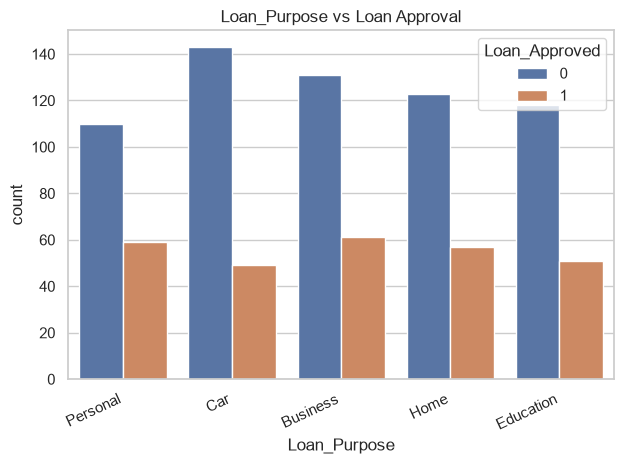

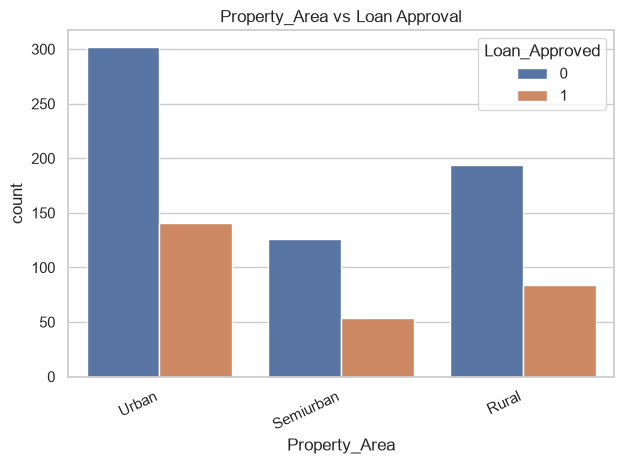

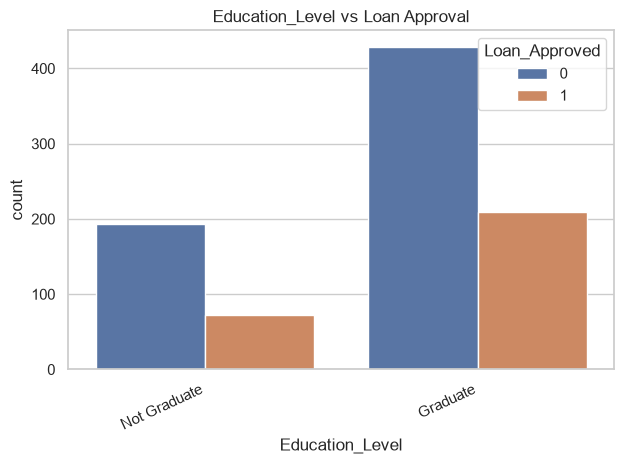

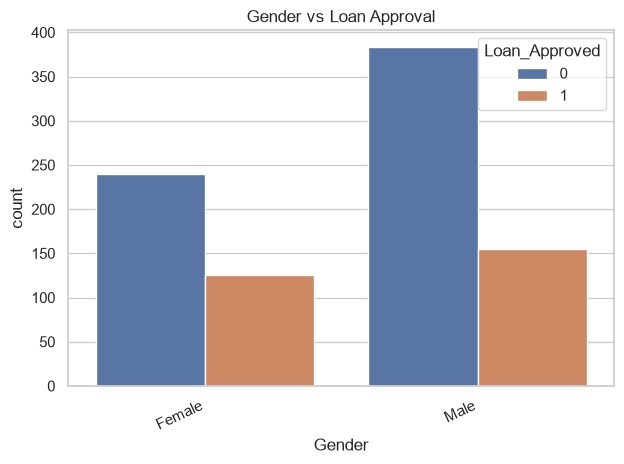

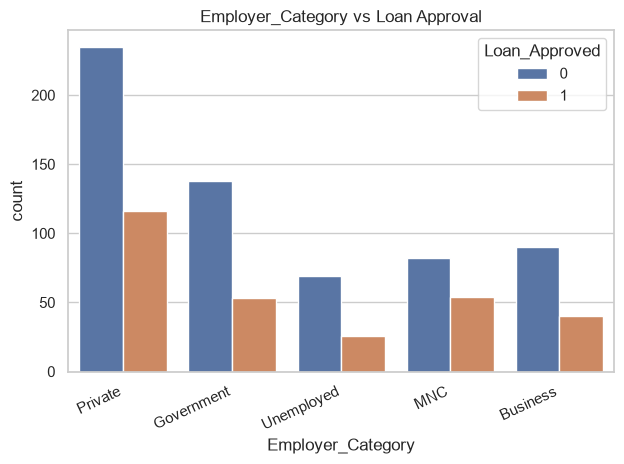

In [10]:
categorical_cols = [
    c for c in ["Employment_Status", "Marital_Status", "Loan_Purpose",
                "Property_Area", "Education_Level", "Gender", "Employer_Category"]
    if c in df.columns
]
for col in categorical_cols:
    sns.countplot(data=df, x=col, hue="Loan_Approved")
    plt.title(f"{col} vs Loan Approval")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


## Train-Test Split

In [11]:
X = df.drop(columns="Loan_Approved")
y = df["Loan_Approved"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (760, 18) Test: (190, 18)


## Preprocessing

In [12]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


## Model Training

In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB()
}

def make_pipeline(estimator, dense=False):
    steps = [("preprocessor", preprocessor)]
    if dense:
        steps.append(("to_dense", FunctionTransformer(
            lambda x: x.toarray() if hasattr(x, "toarray") else x
        )))
    steps.append(("model", estimator))
    return Pipeline(steps)

fitted_models = {}
results = []

for name, estimator in models.items():
    model = make_pipeline(estimator, dense=(name == "Gaussian Naive Bayes"))
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })
    fitted_models[name] = model

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.884,0.852,0.767,0.807,0.921
2,Gaussian Naive Bayes,0.874,0.833,0.750,0.789,0.936
1,KNN,0.800,0.696,0.650,0.672,0.846


## Model Evaluation


Logistic Regression
              precision    recall  f1-score   support

           0       0.90      0.94      0.92       130
           1       0.85      0.77      0.81        60

    accuracy                           0.88       190
   macro avg       0.87      0.85      0.86       190
weighted avg       0.88      0.88      0.88       190



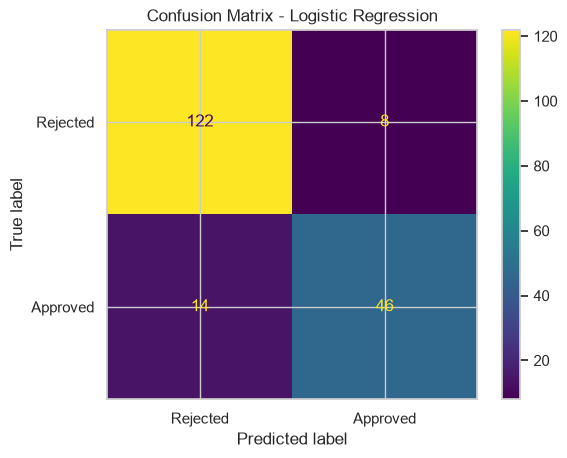


KNN
              precision    recall  f1-score   support

           0       0.84      0.87      0.86       130
           1       0.70      0.65      0.67        60

    accuracy                           0.80       190
   macro avg       0.77      0.76      0.76       190
weighted avg       0.80      0.80      0.80       190



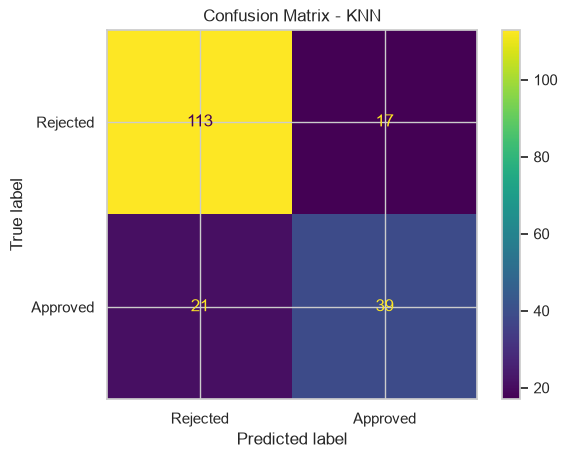


Gaussian Naive Bayes
              precision    recall  f1-score   support

           0       0.89      0.93      0.91       130
           1       0.83      0.75      0.79        60

    accuracy                           0.87       190
   macro avg       0.86      0.84      0.85       190
weighted avg       0.87      0.87      0.87       190



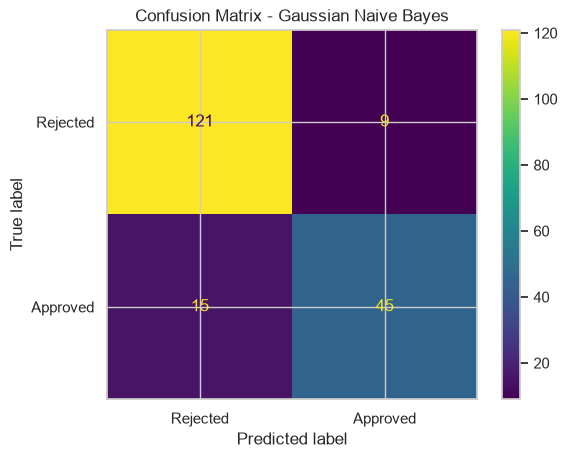

In [14]:
for name, model in fitted_models.items():
    pred = model.predict(X_test)
    print(f"\n{name}")
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Rejected", "Approved"], values_format="d"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.show()


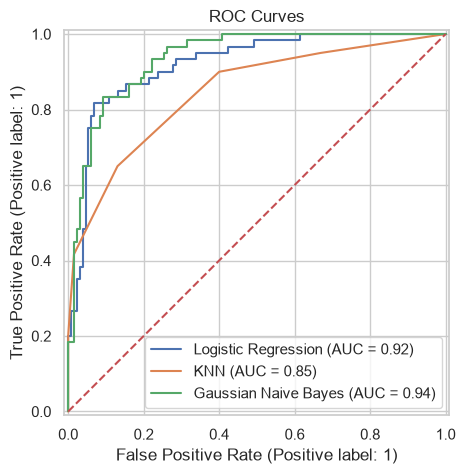

In [15]:
plt.figure(figsize=(7, 5))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "--")
plt.title("ROC Curves")
plt.show()


## Cross-Validation

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

cv_rows = []
for name, estimator in models.items():
    model = make_pipeline(estimator, dense=(name == "Gaussian Naive Bayes"))
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append({
        "Model": name,
        **{f"{metric} mean": scores[f"test_{metric}"].mean() for metric in scoring}
    })

cv_results = pd.DataFrame(cv_rows).sort_values("f1 mean", ascending=False)
display(cv_results.round(3))


,Model,accuracy mean,precision mean,recall mean,f1 mean,roc_auc mean
0,Logistic Regression,0.857,0.800,0.727,0.760,0.922
2,Gaussian Naive Bayes,0.857,0.823,0.697,0.753,0.937
1,KNN,0.818,0.727,0.673,0.696,0.870


## Hyperparameter Tuning

In [17]:
logistic_search = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },
    cv=cv, scoring="f1", n_jobs=-1
)
logistic_search.fit(X_train, y_train)

knn_search = GridSearchCV(
    make_pipeline(KNeighborsClassifier()),
    {
        "model__n_neighbors": [3, 5, 7, 9, 11],
        "model__weights": ["uniform", "distance"]
    },
    cv=cv, scoring="f1", n_jobs=-1
)
knn_search.fit(X_train, y_train)

print("Logistic Regression:", logistic_search.best_params_, round(logistic_search.best_score_, 3))
print("KNN:", knn_search.best_params_, round(knn_search.best_score_, 3))


Logistic Regression: {'model__C': 0.1, 'model__class_weight': 'balanced'} 0.766
KNN: {'model__n_neighbors': 11, 'model__weights': 'uniform'} 0.716


## Final Model Comparison

Cross-validation F1 scores:


,Model,CV F1-score
0,Tuned Logistic Regression,0.766
2,Gaussian Naive Bayes,0.753
1,Tuned KNN,0.716



Selected model: Tuned Logistic Regression

Final Test Results
Accuracy: 0.853
Precision: 0.722
Recall: 0.867
F1-score: 0.788
ROC-AUC: 0.924

Classification Report
              precision    recall  f1-score   support

           0       0.93      0.85      0.89       130
           1       0.72      0.87      0.79        60

    accuracy                           0.85       190
   macro avg       0.83      0.86      0.84       190
weighted avg       0.87      0.85      0.86       190



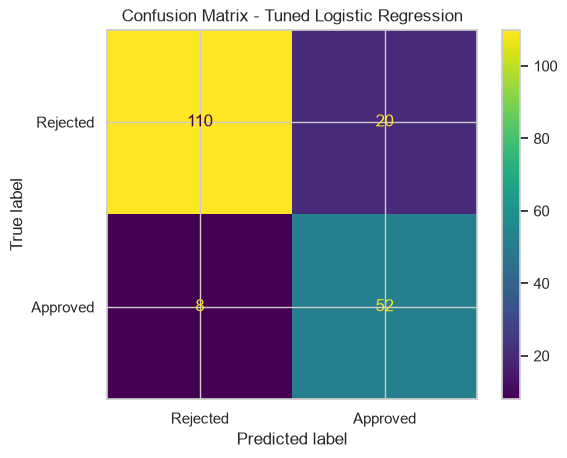

In [18]:

# Select the best model using cross-validation
cv_f1_scores = {
    "Tuned Logistic Regression": logistic_search.best_score_,
    "Tuned KNN": knn_search.best_score_,
    "Gaussian Naive Bayes": cv_results.loc[
        cv_results["Model"] == "Gaussian Naive Bayes", "f1 mean"
    ].iloc[0]
}

final_models = {
    "Tuned Logistic Regression": logistic_search.best_estimator_,
    "Tuned KNN": knn_search.best_estimator_,
    "Gaussian Naive Bayes": fitted_models["Gaussian Naive Bayes"]
}

best_name = max(cv_f1_scores, key=cv_f1_scores.get)
best_model = final_models[best_name]

print("Cross-validation F1 scores:")
display(pd.DataFrame(
    list(cv_f1_scores.items()),
    columns=["Model", "CV F1-score"]
).sort_values("CV F1-score", ascending=False).round(3))

print("\nSelected model:", best_name)

# Final evaluation on the test set
pred = best_model.predict(X_test)
prob = best_model.predict_proba(X_test)[:, 1]

print("\nFinal Test Results")
print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 3))

print("\nClassification Report")
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["Rejected", "Approved"],
    values_format="d"
)
plt.title(f"Confusion Matrix - {best_name}")
plt.show()


## Feature Engineering

In [19]:
# Optional derived features; evaluate them by rerunning the full training pipeline.
engineered_df = df.copy()

if {"Applicant_Income", "Coapplicant_Income"}.issubset(engineered_df.columns):
    engineered_df["Total_Household_Income"] = (
        engineered_df["Applicant_Income"] + engineered_df["Coapplicant_Income"]
    )

if {"Loan_Amount", "Savings"}.issubset(engineered_df.columns):
    engineered_df["Loan_to_Savings_Ratio"] = (
        engineered_df["Loan_Amount"] / engineered_df["Savings"].replace(0, np.nan)
    )

engineered_df.head()


,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved,Total_Household_Income,Loan_to_Savings_Ratio
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,0,19182.0,0.856517
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,0,5539.0,14.994961
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,1,9496.0,2.018420
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,0,22137.0,2.912070
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,1,17507.0,1.357447


## Conclusion

In [21]:

print("Best model:", best_name)
print("Final Test Results:")

print("Accuracy:", round(accuracy_score(y_test, best_model.predict(X_test)), 3))
print("Precision:", round(precision_score(y_test, best_model.predict(X_test), zero_division=0), 3))
print("Recall:", round(recall_score(y_test, best_model.predict(X_test), zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, best_model.predict(X_test), zero_division=0), 3))



Best model: Tuned Logistic Regression
Final Test Results:
Accuracy: 0.853
Precision: 0.722
Recall: 0.867
F1-score: 0.788
